In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="DCgxgbVQavZYKnn8Upk7")
project = rf.workspace("gergess-workspace-ykvgq").project("road-damage-l1ju7-cw7pj")
version = project.version(1)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 31.4 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [typer]
      Successfully uninstalled typer-0.27.2━━━━━━━━━━━━━━━━━━━ 1/3 [typer]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [roboflow]2/3 [roboflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to road-damage-1 in yolov8:: 100%|██████████| 13518/13518 [00:04<00:00, 2909.64it/s]


In [2]:
import glob

found = glob.glob("/kaggle/input/**/best.pt", recursive=True)

def pick(folder):
    m = [p for p in found if f"/{folder}/" in p]
    return m[0] if m else None

MODELS = {
    "yolov5nu_base":  pick("base_yolov5nu"),
    "yolov5nu_tuned": pick("tuned_yolov5nu"),
    "yolov8n_base":   pick("base_yolov8n"),
    "yolo11n_base":   pick("base_yolo11n"),
    "yolo11n_tuned":  pick("tuned_yolo11n"),
}
for k, v in MODELS.items():
    print(f"{k:16s} ->", v)

yolov5nu_base    -> /kaggle/input/datasets/gergeswilliams/road-damage-1/runs/base_yolov5nu/weights/best.pt
yolov5nu_tuned   -> /kaggle/input/datasets/gergeswilliams/road-damage-1/runs/tuned_yolov5nu/weights/best.pt
yolov8n_base     -> /kaggle/input/datasets/gergeswilliams/road-damage-1/runs/base_yolov8n/weights/best.pt
yolo11n_base     -> /kaggle/input/datasets/gergeswilliams/road-damage-1/runs/base_yolo11n/weights/best.pt
yolo11n_tuned    -> /kaggle/input/datasets/gergeswilliams/road-damage-1/runs/tuned_yolo11n/weights/best.pt


In [3]:
import os
for s in ["train", "valid", "test"]:
    p = f"/kaggle/working/road-damage-1/{s}/images"
    print(s, len(os.listdir(p)) if os.path.exists(p) else "MISSING")
print(os.path.exists("/kaggle/working/road-damage-1/data_fixed.yaml"))

train 4930
valid 1146
test 681
False


In [4]:
import os, yaml

D = "/kaggle/working/road-damage-1"
fixed = {"path": D, "train": "train/images", "val": "valid/images",
         "test": "test/images", "nc": 7,
         "names": ['alligator','block','crack','edge','longitudinal','pothole','transverse']}
with open(f"{D}/data_fixed.yaml", "w") as f:
    yaml.dump(fixed, f, sort_keys=False)

print(os.path.exists(f"{D}/data_fixed.yaml"))
for s in ["train", "valid", "test"]:
    p = f"{D}/{s}/labels"
    print(s, "labels:", len(os.listdir(p)) if os.path.exists(p) else "MISSING")

True
train labels: 4930
valid labels: 1146
test labels: 681


In [6]:
!pip install -q ultralytics

In [8]:
import os, glob, time, numpy as np, pandas as pd, torch
from ultralytics import YOLO

DATA = "/kaggle/working/road-damage-1/data_fixed.yaml"
TEST_IMG = "/kaggle/working/road-damage-1/test/images"
TEST_LBL = "/kaggle/working/road-damage-1/test/labels"

imgs = sorted(glob.glob(f"{TEST_IMG}/*.*"))
print("test images:", len(imgs))

def mean_iou(model, conf=0.25):
    ious = []
    for f in imgs:
        lf = f"{TEST_LBL}/{os.path.splitext(os.path.basename(f))[0]}.txt"
        if not os.path.exists(lf) or os.path.getsize(lf) == 0: continue
        r = model.predict(f, imgsz=640, conf=conf, device="cpu", verbose=False)[0]
        h, w = r.orig_shape
        gt = np.loadtxt(lf, ndmin=2)
        gc = gt[:, 0].astype(int)
        xc, yc, bw, bh = gt[:,1]*w, gt[:,2]*h, gt[:,3]*w, gt[:,4]*h
        gb = torch.tensor(np.stack([xc-bw/2, yc-bh/2, xc+bw/2, yc+bh/2], 1), dtype=torch.float32)
        pb, pc = r.boxes.xyxy.cpu(), r.boxes.cls.cpu().int().numpy()
        for i in range(len(gb)):
            m = pc == gc[i]
            if m.sum() == 0: ious.append(0.0); continue
            x1 = torch.maximum(gb[i,0], pb[m,0]); y1 = torch.maximum(gb[i,1], pb[m,1])
            x2 = torch.minimum(gb[i,2], pb[m,2]); y2 = torch.minimum(gb[i,3], pb[m,3])
            inter = (x2-x1).clamp(0) * (y2-y1).clamp(0)
            ag = (gb[i,2]-gb[i,0])*(gb[i,3]-gb[i,1])
            ap = (pb[m,2]-pb[m,0])*(pb[m,3]-pb[m,1])
            ious.append(float((inter/(ag+ap-inter)).max()))
    return float(np.mean(ious))

def cpu_latency_ms(model, n=30):
    sample = imgs[:n]
    for f in sample[:3]: model.predict(f, imgsz=640, device="cpu", verbose=False)  # warmup
    t = time.perf_counter()
    for f in sample: model.predict(f, imgsz=640, device="cpu", verbose=False)
    return (time.perf_counter() - t) / len(sample) * 1000

rows, per_class = [], {}
for name, p in MODELS.items():
    print("==>", name)
    model = YOLO(p)
    m = model.val(data=DATA, split="test", imgsz=640, batch=16, device="cpu", plots=False, verbose=False)
    lat = cpu_latency_ms(model)
    rows.append({
        "model": name, "precision": m.box.mp, "recall": m.box.mr,
        "mAP50": m.box.map50, "mAP50-95": m.box.map,
        "mean_IoU": mean_iou(model),
        "cpu_latency_ms": lat, "cpu_FPS": 1000/lat,
        "size_MB": os.path.getsize(p)/1e6,
        "params_M": sum(x.numel() for x in model.model.parameters())/1e6,
    })
    per_class[name] = dict(zip([model.names[i] for i in m.box.ap_class_index], m.box.maps[m.box.ap_class_index]))

final = pd.DataFrame(rows).round(4)
final.to_csv("/kaggle/working/final_comparison.csv", index=False)
pd.DataFrame(per_class).round(4).to_csv("/kaggle/working/per_class_mAP50-95.csv")
print(final.to_string(index=False))
print(pd.DataFrame(per_class).round(3))

test images: 681
==> yolov5nu_base
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv5n summary (fused): 85 layers, 2,631,461 parameters, 0 gradients, 7.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 328.7±442.4 MB/s, size: 305.0 KB)
val: Scanning /kaggle/working/road-damage-1/test/labels... 681 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 681/681 1.1Kit/s 0.6s0.0ss
val: New cache created: /kaggle/working/road-damage-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 1.8s/it 1:181.9sss
                   all        681       2004      0.607      0.511       0.56      0.338
Speed: 4.0ms preprocess, 94.9ms inference, 0.0ms loss, 1.9ms postprocess per image
==> yolov5nu_tuned
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv5n summary (fused): 85 layers, 2,631,461 parameters, 0 gradients, 7.6 GFLOPs
val: Fast

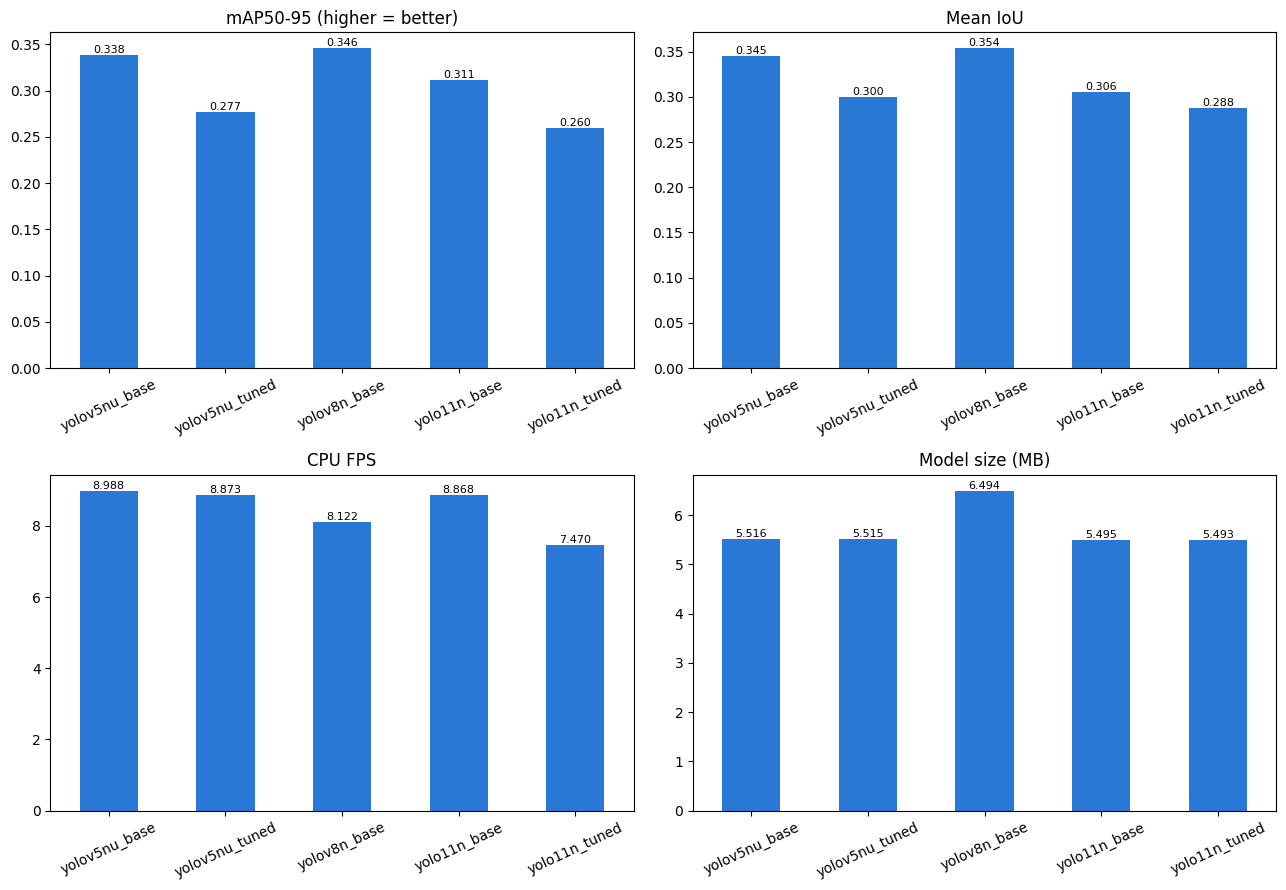

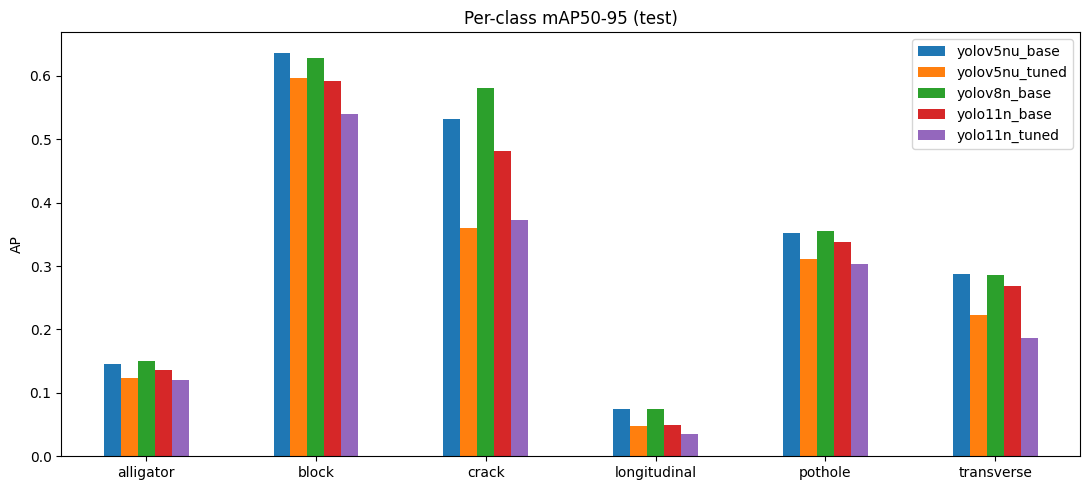

In [9]:
import pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/working/final_comparison.csv").set_index("model")
pc = pd.read_csv("/kaggle/working/per_class_mAP50-95.csv", index_col=0)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, col, t in zip(ax.ravel(), ["mAP50-95", "mean_IoU", "cpu_FPS", "size_MB"],
                     ["mAP50-95 (higher = better)", "Mean IoU", "CPU FPS", "Model size (MB)"]):
    df[col].plot.bar(ax=a, color="#2a78d6", rot=25)
    a.set_title(t); a.set_xlabel("")
    for i, v in enumerate(df[col]): a.text(i, v, f"{v:.3f}" if v < 10 else f"{v:.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig("/kaggle/working/comparison_bars.png", dpi=150); plt.show()

ax = pc.plot.bar(figsize=(11, 5), rot=0)
ax.set_title("Per-class mAP50-95 (test)"); ax.set_ylabel("AP")
plt.tight_layout(); plt.savefig("/kaggle/working/per_class.png", dpi=150); plt.show()